<a href="https://colab.research.google.com/github/MatSantDev/Summit-2026/blob/main/ProjetoSummit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

# ***Classificação da Dieta de Animais com SVM***

### Herbívoro · Carnívoro · Onívoro

</div>

---

### Grupo

- Mateus Santos 11241102520
- Antonio Fonseca 11241102670

### Objetivo

Usar este dataset **Zoo Animal Classification** e treinar um modelo **SVM** para prevêr a **dieta** de um animal a partir das suas características físicas:
- herbivoro(0), carnivero(1) ou onivero(2)

### Por que este dataset?

- Quase todos os atributos são **booleanos**
- **Não tem valores nulos**

### O que alteramos no Dataset?
- criamos a coluna `diet` à mão para cada um dos 101 animais.

## ***Realizando os imports necessarios***

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub
import os

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## ***Baixando o dataset e carregando o arquivo***

In [ ]:
'''
caminho_arquivo = '/kaggle/input/datasets/uciml/zoo-animal-classification/zoo.csv'
df = pd.read_csv(caminho_arquivo)
'''

path = kagglehub.dataset_download("uciml/zoo-animal-classification")
print(path)

df = None
for arquivo in os.listdir(path):
  caminho_path = os.path.join(path, arquivo)
  if "zoo.csv" in arquivo:
    df = pd.read_csv(caminho_path)

print(f'Dataset carregado: {df.shape[0]} animais e {df.shape[1]} colunas')

Using Colab cache for faster access to the 'zoo-animal-classification' dataset.
/kaggle/input/zoo-animal-classification
Dataset carregado: 101 animais e 18 colunas


## ***Rotulagem das dietas***

O dataset original não informa a dieta. Por isso, **classificamos manualmente** cada animal e juntamos essa informação ao DataFrame na *coluna* `diet`.

In [ ]:
diet = {
    'aardvark': 1,
    'antelope': 0,
    'bass': 1,
    'bear': 2,
    'boar': 2,
    'buffalo': 0,
    'calf': 0,
    'carp': 2,
    'catfish': 1,
    'cavy': 0,
    'cheetah': 1,
    'chicken': 2,
    'chub': 1,
    'clam': 1,
    'crab': 1,
    'crayfish': 1,
    'crow': 2,
    'deer': 0,
    'dogfish': 1,
    'dolphin': 1,
    'dove': 0,
    'duck': 2,
    'elephant': 0,
    'flamingo': 2,
    'flea': 1,
    'frog': 1,
    'fruitbat': 0,
    'giraffe': 0,
    'girl': 2,
    'gnat': 2,
    'goat': 0,
    'gorilla': 0,
    'gull': 2,
    'haddock': 1,
    'hamster': 2,
    'hare': 0,
    'hawk': 1,
    'herring': 1,
    'honeybee': 0,
    'housefly': 2,
    'kiwi': 2,
    'ladybird': 1,
    'lark': 2,
    'leopard': 1,
    'lion': 1,
    'lobster': 1,
    'lynx': 1,
    'mink': 1,
    'mole': 1,
    'mongoose': 1,
    'moth': 0,
    'newt': 1,
    'octopus': 1,
    'opossum': 2,
    'oryx': 0,
    'ostrich': 2,
    'parakeet': 2,
    'penguin': 1,
    'pheasant': 2,
    'pike': 1,
    'piranha': 1,
    'pitviper': 1,
    'platypus': 1,
    'polecat': 1,
    'pony': 0,
    'porpoise': 1,
    'puma': 1,
    'pussycat': 1,
    'raccoon': 2,
    'reindeer': 0,
    'rhea': 2,
    'scorpion': 1,
    'seahorse': 1,
    'seal': 1,
    'sealion': 1,
    'seasnake': 1,
    'seawasp': 1,
    'skimmer': 1,
    'skua': 1,
    'slowworm': 1,
    'slug': 2,
    'sole': 1,
    'sparrow': 2,
    'squirrel': 2,
    'starfish': 1,
    'stingray': 1,
    'swan': 2,
    'termite': 0,
    'toad': 1,
    'tortoise': 0,
    'tuatara': 1,
    'tuna': 1,
    'vampire': 1,
    'vole': 0,
    'vulture': 1,
    'wallaby': 0,
    'wasp': 1,
    'wolf': 1,
    'worm': 2,
    'wren': 2
}

df['diet'] = df['animal_name'].map(diet)
animais_ausentes = df[df['diet'].isnull()]['animal_name'].tolist()
print(f"Animais sem classificação (quantidade: {len(animais_ausentes)}):")

Animais sem classificação (quantidade: 0):


## **Quantidade de linhas e colunas**

In [ ]:
linhas, colunas = df.shape
print(f'Linhas (animais): {linhas}')
print(f'Colunas (atributos): {colunas}')

Linhas (animais): 101
Colunas (atributos): 19


## ***Primeiras linhas***

In [ ]:
display(df.head())

,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type,diet
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1,0
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4,1
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1,2
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1,2


## ***Tipos de dados***

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   animal_name  101 non-null    object
 1   hair         101 non-null    int64 
 2   feathers     101 non-null    int64 
 3   eggs         101 non-null    int64 
 4   milk         101 non-null    int64 
 5   airborne     101 non-null    int64 
 6   aquatic      101 non-null    int64 
 7   predator     101 non-null    int64 
 8   toothed      101 non-null    int64 
 9   backbone     101 non-null    int64 
 10  breathes     101 non-null    int64 
 11  venomous     101 non-null    int64 
 12  fins         101 non-null    int64 
 13  legs         101 non-null    int64 
 14  tail         101 non-null    int64 
 15  domestic     101 non-null    int64 
 16  catsize      101 non-null    int64 
 17  class_type   101 non-null    int64 
 18  diet         101 non-null    int64 
dtypes: int64(18), object(1)
memor

## **Estatísticas descritivas**

In [ ]:
display(df.describe())

,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type,diet
count,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000
mean,0.425743,0.198020,0.584158,0.405941,0.237624,0.356436,0.554455,0.603960,0.821782,0.792079,0.079208,0.168317,2.841584,0.742574,0.128713,0.435644,2.831683,1.049505
std,0.496921,0.400495,0.495325,0.493522,0.427750,0.481335,0.499505,0.491512,0.384605,0.407844,0.271410,0.376013,2.033385,0.439397,0.336552,0.498314,2.102709,0.683758
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000,1.000000
50%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,0.000000,2.000000,1.000000
75%,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,1.000000,4.000000,2.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.000000,1.000000,1.000000,1.000000,7.000000,2.000000


## **Valores nulos**

In [ ]:
nulos = df.isnull().sum()
print(f'Total de valores nulos no dataset: {nulos.sum()}')
nulos.to_frame('valores_nulos').T

Total de valores nulos no dataset: 0


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type,diet
valores_nulos,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## **Gráfico de Distribuição**

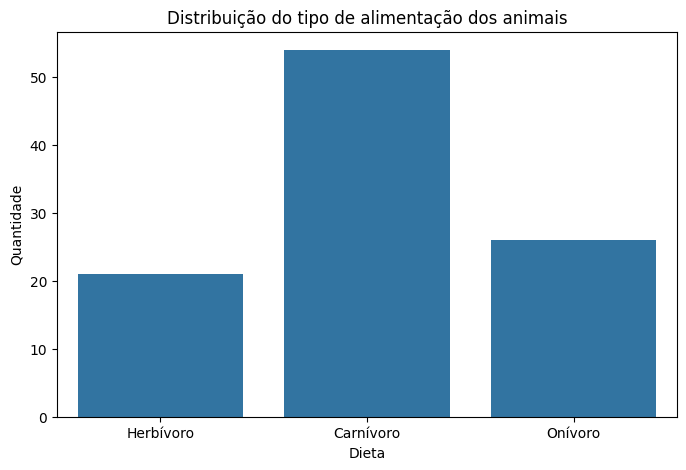

In [ ]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='diet', data=df, order=[0, 1, 2])

plt.title("Distribuição do tipo de alimentação dos animais")
plt.xlabel("Dieta")
plt.ylabel("Quantidade")

ax.set_xticks([0, 1, 2])
ax.set_xticklabels(['Herbívoro', 'Carnívoro', 'Onívoro'])

plt.show()

## ***Matriz de correlação***

Mostra como os atributos se relacionam entre si e com a dieta. Valores próximos de **+1** (vermelho) indicam correlação positiva, e próximos de **−1** (azul), negativa.

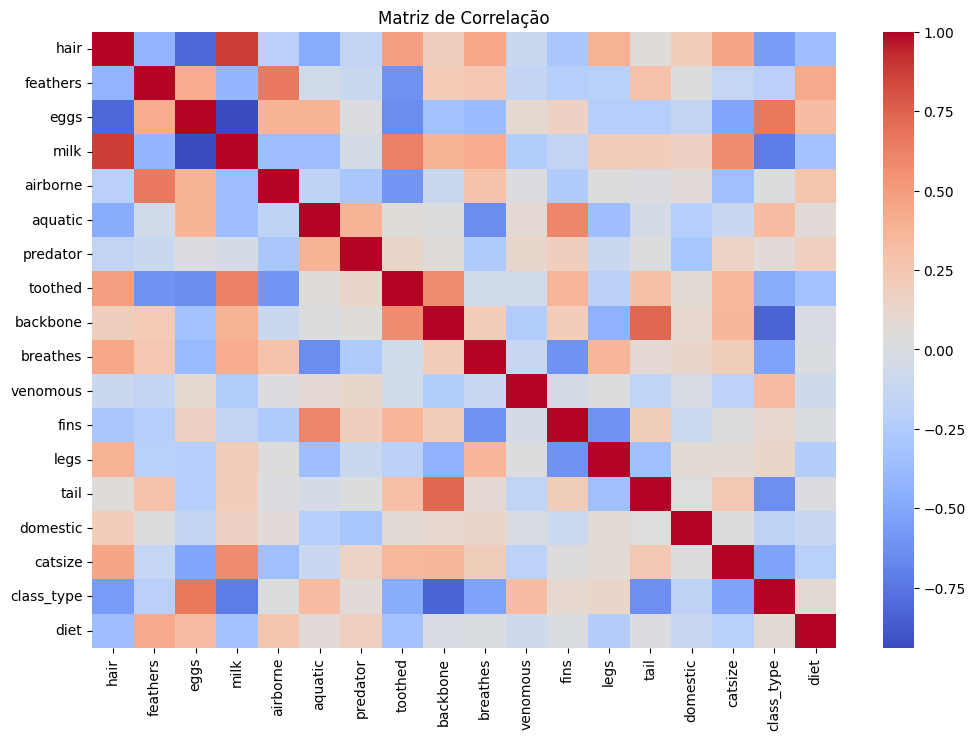

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.drop('animal_name', axis=1).corr(), cmap="coolwarm", annot=False)
plt.title("Matriz de Correlação")
plt.show()

## ***Preparação dos dados***

- **Removemos** `animal_name` (identificador, não é uma característica) e `class_type` (classe taxonômica, que não queremos usar como atalho).
- **Separamos** 80% dos dados para treino e 20% para teste.
- **Normalizamos** com `StandardScaler`. O SVM depende de distâncias, então todos os atributos precisam estar na mesma escala. O scaler é ajustado **somente no treino** para evitar vazamento de dados.

In [ ]:
X = df.drop(columns=['animal_name', 'diet', 'class_type'])
y = df['diet']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'Treino: {X_train.shape[0]} animais')
print(f'Teste:  {X_test.shape[0]} animais')
print(f'Atributos usados ({X.shape[1]}): {", ".join(X.columns)}')

Treino: 80 animais
Teste:  21 animais
Atributos usados (16): hair, feathers, eggs, milk, airborne, aquatic, predator, toothed, backbone, breathes, venomous, fins, legs, tail, domestic, catsize


## ***Comparação de kernels do SVM***

### Kernel Linear

In [ ]:
model_linear = SVC(kernel='linear')
model_linear.fit(X_train_scaled, y_train)

y_pred_linear = model_linear.predict(X_test_scaled)
accuracy_linear = accuracy_score(y_test, y_pred_linear)
print(f'Acurácia do modelo Linear: {accuracy_linear * 100:.2f}%')

Acurácia do modelo Linear: 71.43%


### Kernel Poly

In [ ]:
model_poly = SVC(kernel='poly')
model_poly.fit(X_train_scaled, y_train)

y_pred_poly = model_poly.predict(X_test_scaled)
accuracy_poly = accuracy_score(y_test, y_pred_poly)
print(f'Acurácia do modelo Poly: {accuracy_poly * 100:.2f}%')

Acurácia do modelo Poly: 71.43%


### Kernel RBF

In [ ]:
model_rbf = SVC(kernel='rbf')
model_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = model_rbf.predict(X_test_scaled)
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
print(f'Acurácia do modelo RBF: {accuracy_rbf * 100:.2f}%')

Acurácia do modelo RBF: 71.43%


### Kernel Sigmoid

In [ ]:
model_sigmoid = SVC(kernel='sigmoid')
model_sigmoid.fit(X_train_scaled, y_train)

y_pred_sigmoid = model_sigmoid.predict(X_test_scaled)
accuracy_sigmoid = accuracy_score(y_test, y_pred_sigmoid)
print(f'Acurácia do modelo Sigmoid: {accuracy_sigmoid * 100:.2f}%')

Acurácia do modelo Sigmoid: 71.43%


### Resumo da comparação de kernels

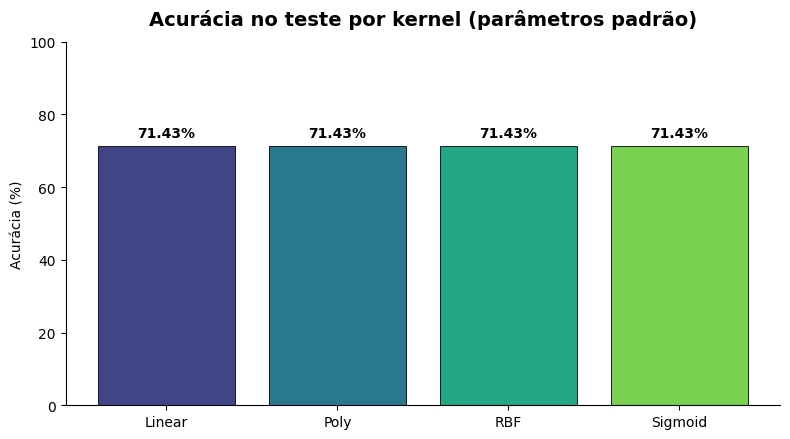

Kernel,Acurácia (%)
Linear,71.43%
Poly,71.43%
RBF,71.43%
Sigmoid,71.43%


In [ ]:
resultados = pd.DataFrame({
    'Kernel': ['Linear', 'Poly', 'RBF', 'Sigmoid'],
    'Acurácia (%)': [accuracy_linear * 100, accuracy_poly * 100,
                     accuracy_rbf * 100, accuracy_sigmoid * 100],
})

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.bar(resultados['Kernel'], resultados['Acurácia (%)'],
                color=sns.color_palette('viridis', 4), edgecolor='black', linewidth=0.6)
ax.bar_label(barras, fmt='%.2f%%', padding=4, fontweight='bold')
ax.set_title('Acurácia no teste por kernel (parâmetros padrão)', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Acurácia (%)')
ax.set_ylim(0, 100)
sns.despine()
plt.tight_layout()
plt.show()

resultados.style.format({'Acurácia (%)': '{:.2f}%'}).hide(axis='index')

## ***Otimização de hiperparâmetros (GridSearchCV)***


In [ ]:
parametros = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.1, 0.01],
    'kernel': ['rbf', 'linear', 'poly', 'sigmoid']
}
grid = GridSearchCV(SVC(), parametros, cv=4, scoring='accuracy', n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print('Melhores parâmetros encontrados:')
for parametro, valor in grid.best_params_.items():
    print(f'   • {parametro}: {valor}')
print(f'\nAcurácia média na validação cruzada (treino): {grid.best_score_ * 100:.2f}%')

Melhores parâmetros encontrados:
   • C: 10
   • gamma: 0.1
   • kernel: sigmoid

Acurácia média na validação cruzada (treino): 78.75%


## ***Avaliação final no conjunto de teste***

In [ ]:
modelo_grid = grid.best_estimator_
y_pred_final = modelo_grid.predict(X_test_scaled)
acc_final = accuracy_score(y_test, y_pred_final)

acc_padrao = max(accuracy_linear, accuracy_poly, accuracy_rbf, accuracy_sigmoid)
print(f'Acurácia final no teste: {acc_final * 100:.2f}%')
print(f'(melhor kernel com parâmetros padrão: {acc_padrao * 100:.2f}% → ganho de {(acc_final - acc_padrao) * 100:+.2f} p.p.)')

Acurácia final no teste: 76.19%
(melhor kernel com parâmetros padrão: 71.43% → ganho de +4.76 p.p.)


## ***Relatório de classificação***

- **Precisão**: dos animais que o modelo colocou em uma classe, quantos realmente eram dela.
- **Recall**: dos animais de uma classe, quantos o modelo encontrou.
- **F1-score**: média harmônica entre precisão e recall.

In [ ]:
NOMES_DIETA = {0: 'Herbívoro', 1: 'Carnívoro', 2: 'Onívoro'}
relatorio = classification_report(y_test, y_pred_final, labels=[0, 1, 2],
                                  target_names=list(NOMES_DIETA.values()),
                                  output_dict=True, zero_division=0)
pd.DataFrame(relatorio).T.style.format('{:.2f}')

,precision,recall,f1-score,support
Herbívoro,0.57,1.00,0.73,4.00
Carnívoro,0.86,0.92,0.89,13.00
Onívoro,0.00,0.00,0.00,4.00
accuracy,0.76,0.76,0.76,0.76
macro avg,0.48,0.64,0.54,21.00
weighted avg,0.64,0.76,0.69,21.00


## **Matriz de Confusão**

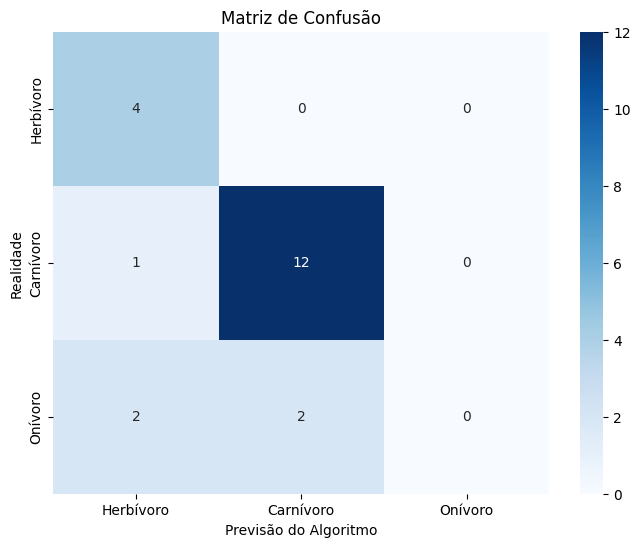

In [ ]:
cm = confusion_matrix(y_test, y_pred_final, labels=[0, 1, 2])

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Herbívoro', 'Carnívoro', 'Onívoro'],
            yticklabels=['Herbívoro', 'Carnívoro', 'Onívoro'])
plt.xlabel('Previsão do Algoritmo')
plt.ylabel('Realidade')
plt.title('Matriz de Confusão')
plt.show()

## ***Quais animais o modelo errou?***

In [ ]:
analise = pd.DataFrame({
    'Animal': df.loc[X_test.index, 'animal_name'].values,
    'Dieta real': y_test.map(NOMES_DIETA).values,
    'Previsão': pd.Series(y_pred_final).map(NOMES_DIETA).values,
})
analise['Resultado'] = (analise['Dieta real'] == analise['Previsão']).map({True: '1', False: '0'})
analise = analise.sort_values('Resultado', ascending=False).reset_index(drop=True)

def destacar(linha):
    cor = '#ff8799' if linha['Resultado'].startswith('0') else '#00a133'
    return [f'background-color: {cor}'] * len(linha)

analise.style.apply(destacar, axis=1).hide(axis='index')

Animal,Dieta real,Previsão,Resultado
dogfish,Carnívoro,Carnívoro,1
aardvark,Carnívoro,Carnívoro,1
goat,Herbívoro,Herbívoro,1
chub,Carnívoro,Carnívoro,1
skimmer,Carnívoro,Carnívoro,1
seawasp,Carnívoro,Carnívoro,1
wasp,Carnívoro,Carnívoro,1
oryx,Herbívoro,Herbívoro,1
seasnake,Carnívoro,Carnívoro,1
cheetah,Carnívoro,Carnívoro,1


## ***Conclusão***

- Criamos manualmente o rótulo de **dieta** para os 101 animais do dataset Zoo.
- Com os **parâmetros padrão**, os kernels tiveram desempenho parecido, em torno de **71%** de acurácia.
- O **GridSearchCV** encontrou uma combinação melhor de `kernel`, `C` e `gamma` e elevou a acurácia no teste para cerca de **76%**.
- O modelo vai muito bem com **carnívoros** (12 de 13 acertos) e **herbívoros** (4 de 4).
- O ponto fraco é a classe **onívoro**: nenhum dos 4 onívoros do teste foi acertado. Faz sentido, porque um onívoro tem características físicas tanto de herbívoros quanto de carnívoros, e nenhum atributo do dataset descreve diretamente o que o animal come.